# 02_Ripple_protect

In [28]:

# --- 12.0 Configuration -----------------------------------------------------------
import os
import json
import numpy as np
import pandas as pd

# Scope: One-shot, domain prompt, single iteration.
ONESHOT_SHOT   = "one"
ONESHOT_PROMPT = "domain"
ITERATION      = 0
WRONG_TOKEN    = "__wrong__"

# Reuse existing saved predictions (no LLM rerun).
# First existing file wins.
PREDICTION_CSV_CANDIDATES = [
    run_path("CrisisNLP_one_shot_domain_predictions.csv"),
    run_path("CrisisNLP_all_predictions_per_instance.csv"),
]

# Ripple grouping:
# One group per true_label among W0-misclassified samples.
# No embeddings, similarity threshold, or minimum group size.

# Protect memory:
# All W0-correct samples in the selected scope.
# No cosine similarity, top-k, or sampling.

# Output files.
OUT_RIPPLE = run_path("CrisisNLP_ripple_sets.csv")
OUT_PROTECT = run_path("CrisisNLP_protect_sets.csv")
OUT_SUMMARY = run_path("CrisisNLP_ripple_protect_summary.csv")

print(
    f"Scope: shot={ONESHOT_SHOT!r} "
    f"prompt={ONESHOT_PROMPT!r} "
    f"iteration={ITERATION}"
)
print("Ripple grouping: by true_label only (one group per class)")
print("Protect: ONE GLOBAL memory = ALL W0-correct samples in scope")



Scope: shot='one' prompt='domain' iteration=0
Ripple grouping: by true_label only (one group per class)
Protect: ONE GLOBAL memory = ALL W0-correct samples in scope


In [29]:
# --- 12.1 Load saved One-shot predictions (reuse; no reclassification) ------------
def _load_predictions():
    for path in PREDICTION_CSV_CANDIDATES:
        if os.path.exists(path):
            df = pd.read_csv(path, dtype=str, keep_default_na=False)
            print(f"[load] using saved predictions: {path}  ({len(df)} rows)")
            return df, path
    if "pred_df" in globals() and isinstance(globals()["pred_df"], pd.DataFrame):
        print("[load] no CSV found; using in-memory pred_df")
        return globals()["pred_df"].astype(str), "<in-memory pred_df>"
    if "PER_INSTANCE_RECORDS" in globals() and len(globals()["PER_INSTANCE_RECORDS"]) > 0:
        print("[load] no CSV found; using in-memory PER_INSTANCE_RECORDS")
        return pd.DataFrame(globals()["PER_INSTANCE_RECORDS"]).astype(str), "<in-memory records>"
    raise FileNotFoundError(
        "No saved prediction CSV found. Run Section 10-11 once to produce "
        + PREDICTION_CSV_CANDIDATES[0] + "."
    )

pred_raw, PRED_SOURCE = _load_predictions()
print("columns:", list(pred_raw.columns))


[load] using saved predictions: /scratch/project_2019963/ablation/Wo_KL CrisisNLP/CrisisNLP_500_run/CrisisNLP_one_shot_domain_predictions.csv  (500 rows)
columns: ['dataset', 'sample_id', 'text', 'true_label', 'predicted_label', 'is_correct', 'is_misclassified', 'invalid_model_output', 'shot', 'prompt', 'iteration', 'raw_model_output', 'exact_messages_json', 'exemplars_json']


In [30]:
# --- 12.2 Filter to scope, drop invalid outputs, split correct vs misclassified ---
REQUIRED = {"sample_id","text","true_label","predicted_label","shot","prompt","iteration"}
missing = REQUIRED - set(pred_raw.columns)
assert not missing, f"Saved predictions missing required columns: {missing}"

def _to_bool(s):
    return s.astype(str).str.strip().str.lower().isin(["true","1","yes"])

d = pred_raw.copy()
d["iteration"] = d["iteration"].astype(str).str.strip()
scoped = d[(d["shot"].astype(str)==ONESHOT_SHOT) &
           (d["prompt"].astype(str)==ONESHOT_PROMPT) &
           (d["iteration"]==str(ITERATION))].copy()

valid_mask = scoped["predicted_label"].astype(str) != WRONG_TOKEN
if "invalid_model_output" in scoped.columns:
    valid_mask &= ~_to_bool(scoped["invalid_model_output"])
valid_df = scoped[valid_mask].copy().reset_index(drop=True)

valid_df["true_label"]      = valid_df["true_label"].astype(str)
valid_df["predicted_label"] = valid_df["predicted_label"].astype(str)
valid_df["is_correct"]       = valid_df["predicted_label"] == valid_df["true_label"]
valid_df["is_misclassified"] = ~valid_df["is_correct"]

dup = valid_df["sample_id"].duplicated().sum()
assert dup == 0, f"sample_id not unique in scope ({dup} duplicates) — check ITERATION."

mis_df     = valid_df[valid_df["is_misclassified"]].copy()   # Ripple pool
correct_df = valid_df[valid_df["is_correct"]].copy()          # Protect pool

print(f"scoped rows: {len(scoped)} -> valid: {len(valid_df)}")
print(f"  misclassified (Ripple pool): {len(mis_df)}")
print(f"  correct       (Protect pool): {len(correct_df)}")
print("\nMisclassified per true_label:")
print(mis_df["true_label"].value_counts().to_string())


scoped rows: 500 -> valid: 499
  misclassified (Ripple pool): 254
  correct       (Protect pool): 245

Misclassified per true_label:
true_label
other_useful_information                             143
not_related_or_irrelevant                             27
donation_needs_or_offers_or_volunteering_services     26
caution_and_advice                                    18
sympathy_and_emotional_support                        14
injured_or_dead_people                                12
missing_trapped_or_found_people                        7
displaced_people_and_evacuations                       4
infrastructure_and_utilities_damage                    3


In [31]:
# Build Ripple groups by true_label
# Each unique true_label corresponds to one Ripple group containing
# all misclassified samples belonging to that class.
ripple_rows = []
group_meta  = {}                 # ripple_group_id -> {true_label, member_ids}
gid = 0
for c in sorted(mis_df["true_label"].unique()):
    members  = mis_df[mis_df["true_label"] == c]
    comp_ids = sorted(members["sample_id"].astype(str).tolist())   # ALL misclassified of this class
    group_meta[gid] = {"true_label": c, "member_ids": comp_ids}
    for sid in comp_ids:
        row = members[members["sample_id"] == sid].iloc[0]
        ripple_rows.append({
            "ripple_group_id": gid,
            "sample_id": sid,
            "text": row["text"],
            "true_label": c,
            "predicted_label": row["predicted_label"],
            "iteration": ITERATION,
            "prompt": ONESHOT_PROMPT,
        })
    gid += 1

ripple_sets = pd.DataFrame(ripple_rows)
print(f"Ripple groups: {len(group_meta)} | Ripple samples grouped: {len(ripple_sets)}")
if len(ripple_sets):
    print(ripple_sets.groupby("true_label")["ripple_group_id"].nunique()
          .rename("n_groups").to_string())

# ---- [check] Ripple construction invariants -------------------------------------
_mis_tl = dict(zip(mis_df["sample_id"].astype(str), mis_df["true_label"].astype(str)))
# (1) every Ripple group contains exactly one unique true_label
for _gid, _meta in group_meta.items():
    _labels = {_mis_tl[_m] for _m in _meta["member_ids"]}
    assert len(_labels) == 1, (
        f"Ripple group {_gid} contains multiple true labels: {_labels}"
    )
if len(ripple_sets):
    assert (ripple_sets.groupby("ripple_group_id")["true_label"].nunique() == 1).all(), (
        "A Ripple group contains multiple true labels."
    )
# (2) each unique true_label maps to exactly one Ripple group (bijection)
_group_labels = [m["true_label"] for m in group_meta.values()]
assert len(_group_labels) == len(set(_group_labels)), (
    "A true_label is split across multiple Ripple groups."
)
assert set(_group_labels) == set(mis_df["true_label"].astype(str).unique()), (
    "Ripple groups do not cover exactly the set of misclassified true_labels."
)
# (3) all misclassified samples are grouped (nothing dropped)
assert len(ripple_sets) == len(mis_df), (
    "Not all misclassified samples were placed into a Ripple group."
)
print("[check] each unique true_label -> exactly one Ripple group: OK")
print("[check] every Ripple group contains all its class's misclassified samples: OK")


Ripple groups: 9 | Ripple samples grouped: 254
true_label
caution_and_advice                                   1
displaced_people_and_evacuations                     1
donation_needs_or_offers_or_volunteering_services    1
infrastructure_and_utilities_damage                  1
injured_or_dead_people                               1
missing_trapped_or_found_people                      1
not_related_or_irrelevant                            1
other_useful_information                             1
sympathy_and_emotional_support                       1
[check] each unique true_label -> exactly one Ripple group: OK
[check] every Ripple group contains all its class's misclassified samples: OK


In [32]:
# Build GLOBAL Protect memory
# Protect is one global memory pool containing all correctly classified
# (W0-correct) samples from the One-shot Domain evaluation (iteration=0).
# The same Protect memory is shared across all Ripple groups.
protect_cols = ["sample_id", "text", "true_label", "predicted_label", "iteration", "prompt"]
protect_rows = []
for _, r in correct_df.iterrows():
    protect_rows.append({
        "sample_id": str(r["sample_id"]),
        "text": r["text"],
        "true_label": str(r["true_label"]),
        "predicted_label": str(r["predicted_label"]),
        "iteration": ITERATION,
        "prompt": ONESHOT_PROMPT,
    })
protect_sets = pd.DataFrame(protect_rows, columns=protect_cols)
print(f"Protect (GLOBAL memory) = ALL W0-correct samples in scope: {len(protect_sets)} samples")


Protect (GLOBAL memory) = ALL W0-correct samples in scope: 245 samples


In [33]:
# Summary table + save all outputs ----------------------------------------
GLOBAL_PROTECT_SIZE = int(len(protect_sets))
summary_rows = []
for gid, meta in group_meta.items():
    summary_rows.append({
        "ripple_group_id": gid,
        "true_label": meta["true_label"],
        "ripple_size": len(meta["member_ids"]),
        "protect_pool_size": GLOBAL_PROTECT_SIZE,   # ONE global Protect memory (same for all groups)
    })

summary_cols = ["ripple_group_id","true_label","ripple_size","protect_pool_size"]
summary = pd.DataFrame(summary_rows, columns=summary_cols)
if len(summary):
    summary = summary.sort_values("ripple_group_id").reset_index(drop=True)

ripple_cols  = ["ripple_group_id","sample_id","text","true_label","predicted_label",
                "iteration","prompt"]
protect_cols = ["sample_id","text","true_label","predicted_label","iteration","prompt"]

(ripple_sets.reindex(columns=ripple_cols) if len(ripple_sets)
 else pd.DataFrame(columns=ripple_cols)).to_csv(OUT_RIPPLE, index=False)
(protect_sets.reindex(columns=protect_cols) if len(protect_sets)
 else pd.DataFrame(columns=protect_cols)).to_csv(OUT_PROTECT, index=False)
summary.to_csv(OUT_SUMMARY, index=False)

print("Saved:")
print(f"  {OUT_RIPPLE}   ({len(ripple_sets)} rows)")
print(f"  {OUT_PROTECT}  ({len(protect_sets)} rows, GLOBAL Protect memory)")
print(f"  {OUT_SUMMARY}  ({len(summary)} groups)")
if len(summary) == 0:
    print("\n(No misclassified samples in scope, so no Ripple groups — "
          "ripple/summary CSVs are written with headers only.)")
else:
    display(summary)


Saved:
  /scratch/project_2019963/ablation/Wo_KL CrisisNLP/CrisisNLP_500_run/CrisisNLP_ripple_sets.csv   (254 rows)
  /scratch/project_2019963/ablation/Wo_KL CrisisNLP/CrisisNLP_500_run/CrisisNLP_protect_sets.csv  (245 rows, GLOBAL Protect memory)
  /scratch/project_2019963/ablation/Wo_KL CrisisNLP/CrisisNLP_500_run/CrisisNLP_ripple_protect_summary.csv  (9 groups)


,ripple_group_id,true_label,ripple_size,protect_pool_size
0,0,caution_and_advice,18,245
1,1,displaced_people_and_evacuations,4,245
2,2,donation_needs_or_offers_or_volunteering_services,26,245
3,3,infrastructure_and_utilities_damage,3,245
4,4,injured_or_dead_people,12,245
5,5,missing_trapped_or_found_people,7,245
6,6,not_related_or_irrelevant,27,245
7,7,other_useful_information,143,245
8,8,sympathy_and_emotional_support,14,245


In [34]:
# Sanity checks (Ripple by true_label; Protect = ALL W0-correct global) ---
mis_ids     = set(mis_df["sample_id"].astype(str))       # W0-misclassified in scope
correct_ids = set(correct_df["sample_id"].astype(str))   # W0-correct in scope
ripple_ids  = set(ripple_sets["sample_id"].astype(str)) if len(ripple_sets) else set()
protect_ids = set(protect_sets["sample_id"].astype(str)) if len(protect_sets) else set()

# (a) no duplicate sample IDs in either set
if len(ripple_sets):
    assert not ripple_sets["sample_id"].astype(str).duplicated().any(), "duplicate Ripple sample IDs"
if len(protect_sets):
    assert not protect_sets["sample_id"].astype(str).duplicated().any(), "duplicate Protect sample IDs"

# (b) Ripple IDs == ALL W0-misclassified IDs ; Protect IDs == ALL W0-correct IDs (in scope)
assert ripple_ids == mis_ids,      "Ripple IDs != all W0-misclassified IDs in scope"
assert protect_ids == correct_ids, "Protect IDs != all W0-correct IDs in scope"

# (c) Ripple and Protect are disjoint
assert not (ripple_ids & protect_ids), "Ripple ∩ Protect is non-empty"

# (d) Ripple grouping invariants (construction is unchanged)
if len(ripple_sets):
    # every misclassified sample appears in exactly one Ripple group
    grp_of = ripple_sets.groupby("sample_id")["ripple_group_id"].nunique()
    assert (grp_of == 1).all(), "a misclassified sample appears in >1 Ripple group"
    assert len(ripple_sets) == len(mis_ids), "not every misclassified sample is grouped exactly once"
    # every Ripple group contains exactly one true_label
    assert (ripple_sets.groupby("ripple_group_id")["true_label"].nunique() == 1).all(), \
        "a Ripple group contains multiple true_labels"
    # every true_label maps to exactly one Ripple group (bijection)
    assert (ripple_sets.groupby("true_label")["ripple_group_id"].nunique() == 1).all(), \
        "a true_label maps to multiple Ripple groups"
    _labels = [m["true_label"] for m in group_meta.values()]
    assert len(_labels) == len(set(_labels)) == len(set(mis_df["true_label"].astype(str))), \
        "Ripple groups are not a bijection with the misclassified true_labels"

# (e) Protect coverage = 100% of W0-correct samples
coverage = (len(protect_ids) / len(correct_ids)) if correct_ids else 1.0
assert abs(coverage - 1.0) < 1e-12, \
    f"Protect coverage != 100% ({len(protect_ids)}/{len(correct_ids)})"

total = len(valid_df)
print("ALL SANITY CHECKS PASSED.")
print(f"  Total valid (in scope)   : {total}")
print(f"  W0 wrong  / Ripple       : {len(mis_ids)}")
print(f"  W0 correct / Protect     : {len(correct_ids)}")
print(f"  Protect coverage         : {len(protect_ids)}/{len(correct_ids)} = {coverage*100:.1f}%")
print(f"  Ripple ∩ Protect         : {len(ripple_ids & protect_ids)}")


ALL SANITY CHECKS PASSED.
  Total valid (in scope)   : 499
  W0 wrong  / Ripple       : 254
  W0 correct / Protect     : 245
  Protect coverage         : 245/245 = 100.0%
  Ripple ∩ Protect         : 0


In [35]:
# Inspect example Ripple groups + global Protect memory --------------------
def _short(t, n=150):
    t = str(t).replace("\n", " ")
    return t if len(t) <= n else t[:n] + "..."

if len(summary) == 0:
    print("No Ripple groups were formed (no misclassified samples in the current scope).")
else:
    show = summary.sort_values("ripple_size", ascending=False)["ripple_group_id"].tolist()[:4]
    for gid in show:
        meta = group_meta[gid]
        print("="*84)
        print(f"RIPPLE GROUP {gid} | true_label={meta['true_label']} "
              f"| size={len(meta['member_ids'])}")
        rg = ripple_sets[ripple_sets["ripple_group_id"] == gid]
        for _, r in rg.iterrows():
            print(f"  [MIS ] id={r['sample_id']:<14} pred={r['predicted_label']:<26}")
            print(f"         {_short(r['text'])}")

print("="*84)
print(f"GLOBAL PROTECT MEMORY (ALL W0-correct samples): {len(protect_sets)} samples")
for _, r in protect_sets.head(8).iterrows():
    print(f"  [KEEP] id={r['sample_id']:<14} true={r['true_label']:<26} pred={r['predicted_label']:<26}")
    print(f"         {_short(r['text'])}")
if len(protect_sets) > 8:
    print(f"  ... and {len(protect_sets) - 8} more")

print("\nStopping here as requested: Ripple sets + GLOBAL Protect memory built and saved.")
print("FiNE localization and model editing are NOT implemented in this section.")


RIPPLE GROUP 7 | true_label=other_useful_information | size=143
  [MIS ] id='382890186084196352' pred=infrastructure_and_utilities_damage
         New #Earthquake #Pasthour M 3.0, Virgin Islands region http://t.co/DbgFOZKIF8
  [MIS ] id='383103922753110016' pred=infrastructure_and_utilities_damage
         Still astonished at what the Earth can do. In regards to the new island near #Pakistan. Amazing power. My thoughts go out to those affected.
  [MIS ] id='383204606190157824' pred=infrastructure_and_utilities_damage
         #earthquake #NZ: Magnitude 2.4, Thursday, September 26 2013 at 11:51:53 pm (NZST), 5 km south-east of Seddon http://t.co/XoFtyH69tt
  [MIS ] id='383505346230091776' pred=injured_or_dead_people    
         RT @q_nida: #Balochistan quake: Aftershock of magnitude 5 hits #Awaran http://t.co/22gFJqlEJY … #Islamabad
  [MIS ] id='383657919645904897' pred=infrastructure_and_utilities_damage
         RT @EarthAlerts: #earthquake: M 3.1 - South-America Chile [Atacama] Vall

In [36]:
# Show results: Ripple sets & GLOBAL Protect memory -----------------------
# Uses the in-memory dataframes if present, otherwise reads the saved CSVs,
# so it runs both right after Section 12 and standalone.
import os
import pandas as pd

def _get(mem_name, csv_path):
    obj = globals().get(mem_name)
    if isinstance(obj, pd.DataFrame):
        return obj.copy()
    return pd.read_csv(csv_path) if os.path.exists(csv_path) else pd.DataFrame()

_r_ripple  = _get("ripple_sets",  run_path("CrisisNLP_ripple_sets.csv"))
_r_protect = _get("protect_sets", run_path("CrisisNLP_protect_sets.csv"))
assert len(_r_ripple), "No Ripple rows found (run Section 12 first, or check the CSV path)."

# One row per Ripple group: true_label, ripple size. Protect is a single GLOBAL pool.
_r_grp = (_r_ripple.groupby(["ripple_group_id", "true_label"])
                   .size().rename("ripple_size").reset_index())
_r_grp = _r_grp.sort_values("ripple_group_id").reset_index(drop=True)

print(f"Ripple groups: {_r_grp['ripple_group_id'].nunique()} | "
      f"unique true_labels: {_r_ripple['true_label'].nunique()} | "
      f"misclassified grouped: {len(_r_ripple)}")
print(f"GLOBAL Protect memory: {len(_r_protect)} W0-correct samples "
      f"(one pool shared by all groups)\n")
print("Per-group result (each true_label = exactly one Ripple group):")
print(_r_grp.to_string(index=False))

# Invariant check on the actual result
_pl = _r_ripple.groupby("true_label")["ripple_group_id"].nunique()
assert (_pl == 1).all(), "Some true_label maps to more than one Ripple group!"
assert (_r_ripple.groupby("ripple_group_id")["true_label"].nunique() == 1).all(), \
    "Some Ripple group mixes true_labels!"
print("\n[invariant] each unique true_label -> exactly one Ripple group "
      "containing all its misclassified samples: OK")

# A few example groups with their members
def _short(t, n=120):
    t = str(t).replace("\n", " ")
    return t if len(t) <= n else t[:n] + "..."
print("\nExample groups:")
for gid in _r_grp.sort_values("ripple_size", ascending=False)["ripple_group_id"].tolist()[:3]:
    g = _r_ripple[_r_ripple["ripple_group_id"] == gid]
    print("=" * 80)
    print(f"RIPPLE GROUP {gid} | true_label={g['true_label'].iloc[0]} | size={len(g)}")
    for _, r in g.iterrows():
        print(f"  id={str(r['sample_id']):<12} pred={str(r['predicted_label']):<20} {_short(r['text'])}")


Ripple groups: 9 | unique true_labels: 9 | misclassified grouped: 254
GLOBAL Protect memory: 245 W0-correct samples (one pool shared by all groups)

Per-group result (each true_label = exactly one Ripple group):
 ripple_group_id                                        true_label  ripple_size
               0                                caution_and_advice           18
               1                  displaced_people_and_evacuations            4
               2 donation_needs_or_offers_or_volunteering_services           26
               3               infrastructure_and_utilities_damage            3
               4                            injured_or_dead_people           12
               5                   missing_trapped_or_found_people            7
               6                         not_related_or_irrelevant           27
               7                          other_useful_information          143
               8                    sympathy_and_emotional_support  

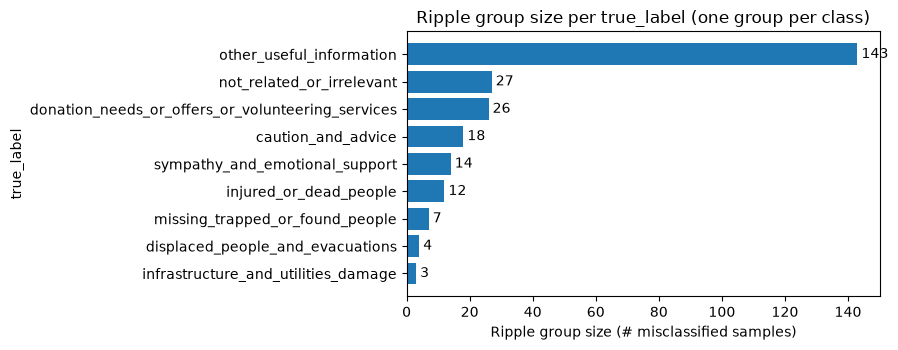

In [37]:
# Optional chart: Ripple group size per true_label -----------------------
import matplotlib.pyplot as plt

_order = _r_grp.sort_values("ripple_size", ascending=False)
fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * len(_order))))
ax.barh(_order["true_label"].astype(str), _order["ripple_size"])
ax.invert_yaxis()
ax.set_xlabel("Ripple group size (# misclassified samples)")
ax.set_ylabel("true_label")
ax.set_title("Ripple group size per true_label (one group per class)")
for _y, _v in enumerate(_order["ripple_size"]):
    ax.text(_v, _y, f" {int(_v)}", va="center")
plt.tight_layout()
plt.show()
